# Exploratory Data Analysis

In [336]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [337]:
features = pd.read_csv("../data/silver/progenitor_features.csv")
outcomes = pd.read_csv("../data/silver/engine_outcomes.csv")

print(f"Progenitor features: {features.shape[0]} rows, {features.shape[1]} columns")
display(features.head())

print(f"Engine outcomes: {outcomes.shape[0]} rows, {outcomes.shape[1]} columns")
display(outcomes.head())

Progenitor features: 200 rows, 48 columns


,model,progenitor_family,zams_mass_msun,central_a_bar,central_density_g_cm3,central_entropy,central_log10_density,central_log10_temperature,central_temperature_k,central_y_e,...,xi_2p0,xi_2p5,xi_3p0,xi_4p0,ye_at_1p5_msun,ye_at_2p0_msun,ye_at_2p5_msun,ye_at_3p0_msun,ye_at_4p0_msun,zone_count
0,s9.0,s,9.00,60.863318,1.634080e+10,0.532258,10.213273,9.849083,7.064521e+09,0.430050,...,0.000046,0.000038,0.000036,0.000036,0.499302,0.816330,0.816337,0.816341,0.816346,1409
1,s9.25,s,9.25,60.038739,1.869078e+10,0.540415,10.271627,9.879118,7.570383e+09,0.428927,...,0.000075,0.000047,0.000042,0.000040,0.499291,0.822502,0.822552,0.822569,0.822587,1343
2,s9.5,s,9.50,59.988038,1.777634e+10,0.540496,10.249842,9.870045,7.413869e+09,0.430310,...,0.002181,0.000062,0.000048,0.000043,0.499302,0.499932,0.831080,0.831134,0.831180,1262
3,s9.75,s,9.75,59.921011,1.469587e+10,0.542151,10.167195,9.840276,6.922700e+09,0.432666,...,0.005654,0.000103,0.000055,0.000044,0.499301,0.499933,0.839144,0.839212,0.839242,1138
4,s10.0,s,10.00,58.790510,1.504105e+10,0.558971,10.177278,9.862500,7.286190e+09,0.432718,...,0.007146,0.000204,0.000051,0.000038,0.499163,0.499358,0.843133,0.843248,0.843264,1093


Engine outcomes: 948 rows, 14 columns


,model,progenitor_family,zams_mass_msun,engine,result_model_name,outcome,label_ns_vs_bh,e_exp_foe,m_fallback_msun,m_mass_cut_after_fb_msun,m_outside_alpha_fb_msun,m_outside_ni_fb_msun,m_outside_tr_fb_msun,m_special_msun
0,s12.25,s,12.25,N20,w12.25,NS,0,1.44,0.000654,1.558,0.063818,0.053176,0.035361,1.656
1,s12.5,s,12.50,N20,w12.5,NS,0,1.44,0.000777,1.577,0.063467,0.058000,0.033674,1.674
2,s12.75,s,12.75,N20,w12.75,NS,0,1.29,0.000861,1.627,0.057211,0.065380,0.021688,1.709
3,s13.0,s,13.00,N20,w13.0,NS,0,1.32,0.000825,1.662,0.058022,0.074636,0.019176,1.742
4,s13.1,s,13.10,N20,s13.1,NS,0,1.22,0.001162,1.591,0.056385,0.061225,0.024855,1.674


In [338]:
print(f"Unique progenitors in features: {features['model'].nunique()}")
print("\nUnique progenitors by engine:")
for engine in outcomes["engine"].unique():
    engine_rows = outcomes[outcomes["engine"] == engine]
    print(f"{engine}: {engine_rows['model'].nunique()}")

Unique progenitors in features: 200

Unique progenitors by engine:
N20: 187
S19.8: 187
W15: 187
W18: 187
W20: 187
Z9.6: 13


`Z9.6` has 13 progenitors, while each of the other five engines has 187. This project uses `N20`, `W18`, `W15`, and `S19.8` to define the target.

In [339]:
SELECTED_ENGINES = ["N20", "W18", "W15", "S19.8"]
RANDOM_SEED = 42

In [340]:
print("Engine   BH   NS")
for engine in SELECTED_ENGINES:
    engine_outcomes = outcomes[outcomes["engine"] == engine]
    bh_count = (engine_outcomes["outcome"] == "BH").sum()
    ns_count = (engine_outcomes["outcome"] == "NS").sum()
    print(f"{engine:<7} {bh_count:>3}  {ns_count:>3}")

Engine   BH   NS
N20      82  105
W18     105   82
W15     113   74
S19.8    78  109


`N20` and `S19.8` have more `NS` outcomes, while `W18` and `W15` have more `BH` outcomes. The class balance differs across engines.

In [341]:
missing_features = features.isna().sum()
print("Missing values in progenitor features:")
print(missing_features[missing_features > 0])

print("Missing values in columns used for the target:")
print(outcomes[["model", "engine", "outcome"]].isna().sum())

Missing values in progenitor features:
surface_fe56    200
dtype: int64
Missing values in columns used for the target:
model      0
engine     0
outcome    0
dtype: int64


`surface_fe56` is listed in the original profile, but its value is `---` at the surface of every progenitor. Silver keeps it missing. I remove it from the EDA table after checking the missing values. I also remove `zone_count`, which describes the profile resolution rather than a physical property of the star. The columns used for the target are complete.

In [342]:
features = features.drop(columns=["surface_fe56", "zone_count"])
print(f"Features after dropping unused columns: {features.shape[1]} columns")

Features after dropping unused columns: 46 columns


In [343]:
reference_models = outcomes[outcomes["engine"] == "N20"]["model"]
print(f"Size of rows (progenitors): {reference_models.shape[0]}")

print("\nEngine   Same models   Duplicates")
for engine in SELECTED_ENGINES:
    engine_models = outcomes[outcomes["engine"] == engine]["model"]
    same_models = engine_models.isin(reference_models).all()
    duplicates = engine_models.duplicated().any()
    print(f"{engine:<7} {str(same_models):<13} {duplicates}")

Size of rows (progenitors): 187

Engine   Same models   Duplicates
N20     True          False
W18     True          False
W15     True          False
S19.8   True          False


The four selected engines contain the same 187 progenitors, with no duplicate models.

Each of the four selected engines contributes to a weighted BH score. The weights are 0.30 for `N20`, 0.30 for `W18`, 0.20 for `W15`, and 0.20 for `S19.8`. For each progenitor, `target_score` is the sum of the weights of the engines that predict BH. A score of 0 means all four predict NS, while 1 means all four predict BH.

In [344]:
ENGINE_WEIGHTS = {"N20": 0.30, "W18": 0.30, "W15": 0.20, "S19.8": 0.20}
target_rows = []

for model in reference_models:
    row = {"model": model, "target_score": 0.0}
    for engine, weight in ENGINE_WEIGHTS.items():
        engine_row = outcomes[(outcomes["model"] == model) & (outcomes["engine"] == engine)]
        result = engine_row["outcome"].iloc[0] # The prediction of a specific engine
        row[engine] = result
        if result == "BH":
            row["target_score"] += weight
    row["target_score"] = round(row["target_score"], 2)
    target_rows.append(row)

target_scores = pd.DataFrame(target_rows)
print(f"Progenitors with a weighted target: {len(target_scores)}")
display(target_scores.sample(5, random_state=RANDOM_SEED))

Progenitors with a weighted target: 187


,model,target_score,N20,W18,W15,S19.8
185,s100,0.5,NS,BH,BH,NS
78,s20.5,0.0,NS,NS,NS,NS
55,s18.2,0.0,NS,NS,NS,NS
137,s26.4,0.2,NS,NS,BH,NS
161,s28.8,1.0,BH,BH,BH,BH


Progenitors by target score:
target_score
0.0    74
0.2     8
0.5    20
0.7     3
0.8     7
1.0    75
Name: count, dtype: int64
Unanimous outcomes: 149 of 187


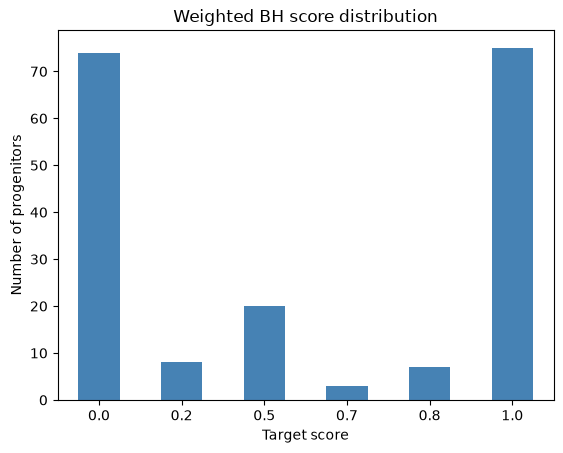

In [345]:
score_counts = target_scores["target_score"].value_counts().sort_index()
print("Progenitors by target score:")
print(score_counts)
unanimous_count = score_counts.loc[0.0] + score_counts.loc[1.0]
print(f"Unanimous outcomes: {unanimous_count} of {len(target_scores)}")

score_counts.plot.bar(color="steelblue")
plt.title("Weighted BH score distribution")
plt.xlabel("Target score")
plt.ylabel("Number of progenitors")
plt.xticks(rotation=0)
plt.show()

For 149 of the 187 progenitors, all four selected engines agree (score 0.0 or 1.0). The remaining 38 show disagreement between engines.

## Features and target score

I match each progenitor's pre-collapse features with its weighted score using `model`.

In [346]:
eda_data = features.merge(target_scores[["model", "target_score"]], on="model")
print(f"Progenitors in the analysis: {len(eda_data)}")

Progenitors in the analysis: 187


## Selected pre-collapse features

[Sukhbold et al. (2016)](https://doi.org/10.3847/0004-637X/821/1/38) show that initial mass alone does not determine the outcome. They emphasize core compactness and the structure around the iron core. I start with eight related properties to explore these patterns. The plots don't rank feature importance.

### What the eight columns mean

These values describe the progenitor before the engine outcome. The definitions follow [`build_silver.py`](../src/build_silver.py).

| Column | Physical meaning |
| --- | --- |
| `zams_mass_msun` | Initial stellar mass, in solar masses, read from the model name. |
| `final_mass_msun` | Total mass in the pre-supernova profile, in solar masses. It is not the remnant mass. |
| `helium_core_mass_msun` | Outermost mass coordinate where the hydrogen fraction is at most 20%, in solar masses. |
| `co_core_mass_msun` | Outermost mass coordinate where the helium fraction is at most 20%, in solar masses. |
| `xi_2p5` | Compactness of the inner 2.5 solar masses. A larger value means this mass fits within a smaller radius. |
| `entropy_at_2p0_msun` | Specific entropy near the mass shell enclosing 2.0 solar masses. |
| `log10_density_at_2p5_msun` | Base-10 logarithm of density near the mass shell enclosing 2.5 solar masses. The original density is in g/cm³. |
| `central_density_g_cm3` | Density in the innermost zone of the pre-supernova profile, in g/cm³. |

The helium and CO core thresholds follow [Sukhbold et al. (2016), Table 2](https://doi.org/10.3847/0004-637X/821/1/38).

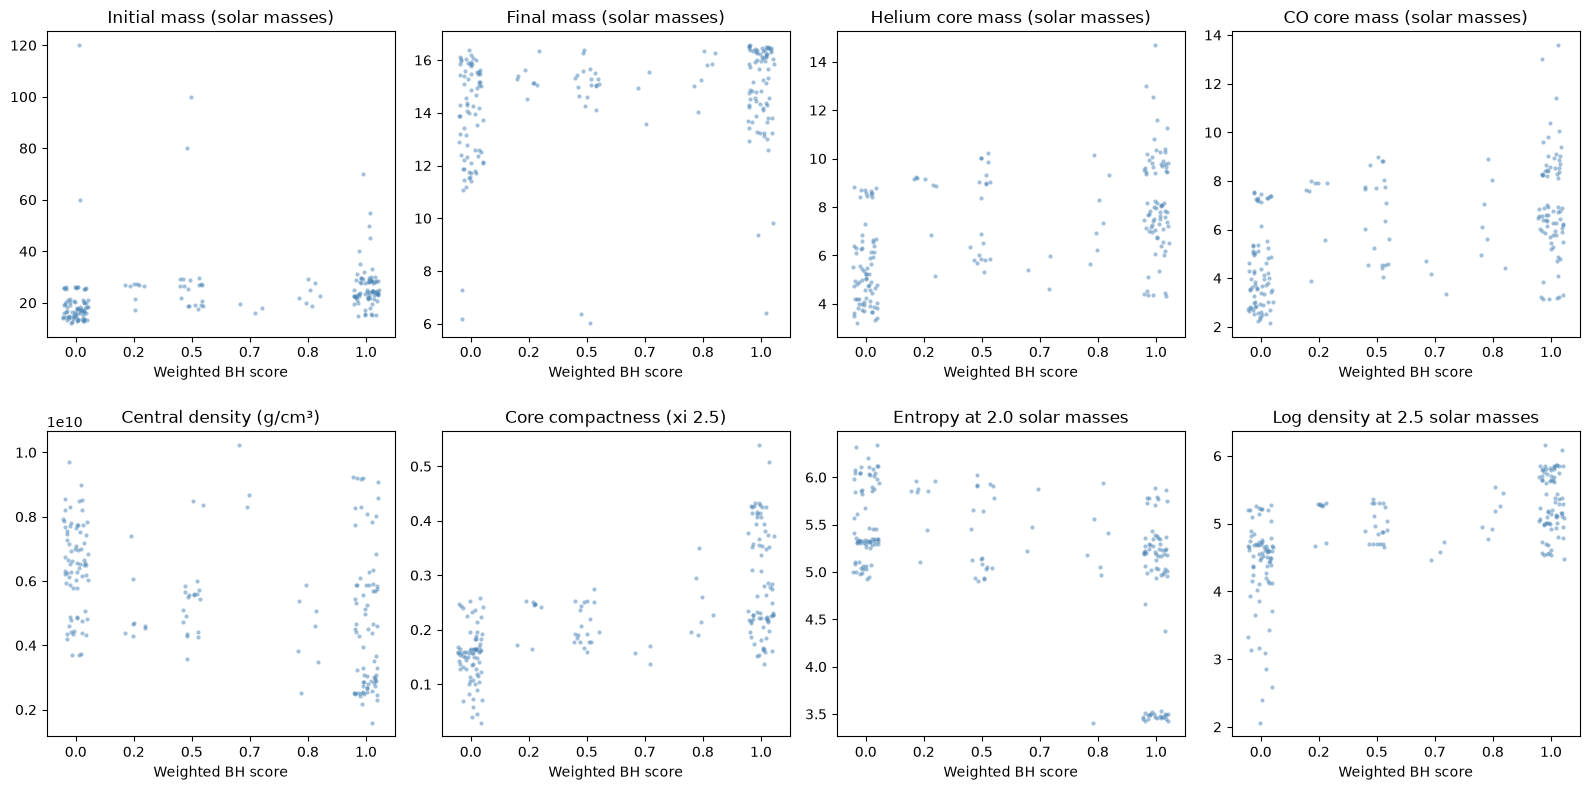

In [347]:
selected_features = {
    "zams_mass_msun": "Initial mass (solar masses)",
    "final_mass_msun": "Final mass (solar masses)",
    "helium_core_mass_msun": "Helium core mass (solar masses)",
    "co_core_mass_msun": "CO core mass (solar masses)",
    "central_density_g_cm3": "Central density (g/cm³)",
    "xi_2p5": "Core compactness (xi 2.5)",
    "entropy_at_2p0_msun": "Entropy at 2.0 solar masses",
    "log10_density_at_2p5_msun": "Log density at 2.5 solar masses",
}

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (column, label) in zip(axes.flat, selected_features.items()):
    sns.stripplot(data=eda_data, x="target_score", y=column, jitter=0.22, alpha=0.5, size=3, ax=ax, color="steelblue")
    ax.set_title(label)
    ax.set_xlabel("Weighted BH score")
    ax.set_ylabel("")

fig.tight_layout()
plt.show()

### Features and engine agreement

Score 0 means all four engines predict NS, and score 1 means all four predict BH. Most stars are in these two groups. The intermediate scores have fewer stars, so I focus on the clearer comparison between 0 and 1.

- **Initial mass:** The two groups share many masses. Higher masses are more common at score 1, but some very massive stars have score 0.
- **Final mass:** Higher values appear somewhat more often at score 1, but there is a lot of overlap.
- **Helium core mass:** Below about 5 solar masses, score 0 is more common. Above that, both groups appear.
- **CO core mass:** All stars below 3 solar masses have score 0 in this sample. At higher masses, the groups overlap.
- **Central density:** Below about 3 × 10^9 g/cm³, nearly all stars have score 1. At higher densities, both groups appear.
- **Core compactness at 2.5 solar masses:** Below 0.2, score 0 is more common. Above 0.2, score 1 is more common. There are exceptions on both sides.
- **Entropy at 2.0 solar masses:** The group near 3.5 is almost entirely at score 1. Then both groups appear.
- **Log density at 2.5 solar masses:** Below about 4.5, almost all stars have score 0. Higher values appear more often at score 1, but the groups overlap.

## Summary of selected features

I review the ranges and scales of the eight selected variables before comparing how they vary together.

In [348]:
display(eda_data[list(selected_features)].describe().T)

,count,mean,std,min,25%,50%,75%,max
zams_mass_msun,187.0,2.387701e+01,1.266154e+01,1.225000e+01,1.735000e+01,2.200000e+01,2.665000e+01,1.200000e+02
final_mass_msun,187.0,1.445443e+01,2.010681e+00,6.035574e+00,1.366710e+01,1.504086e+01,1.588176e+01,1.656270e+01
helium_core_mass_msun,187.0,7.008271e+00,2.219928e+00,3.219875e+00,5.177725e+00,6.847200e+00,8.747995e+00,1.468022e+01
co_core_mass_msun,187.0,5.818720e+00,2.240342e+00,2.166162e+00,3.927017e+00,5.775000e+00,7.473670e+00,1.358000e+01
central_density_g_cm3,187.0,5.530679e+09,1.943159e+09,1.596305e+09,4.286551e+09,5.593488e+09,6.959510e+09,1.022630e+10
xi_2p5,187.0,2.213852e-01,9.645163e-02,2.954176e-02,1.594045e-01,1.960455e-01,2.523476e-01,5.389015e-01
entropy_at_2p0_msun,187.0,5.186911e+00,7.381165e-01,3.409459e+00,5.028996e+00,5.292712e+00,5.736775e+00,6.338745e+00
log10_density_at_2p5_msun,187.0,4.884837e+00,6.716980e-01,2.062898e+00,4.592126e+00,4.920163e+00,5.285125e+00,6.158803e+00


## Distributions of selected features

I use histograms to inspect the range and shape of the eight selected features.

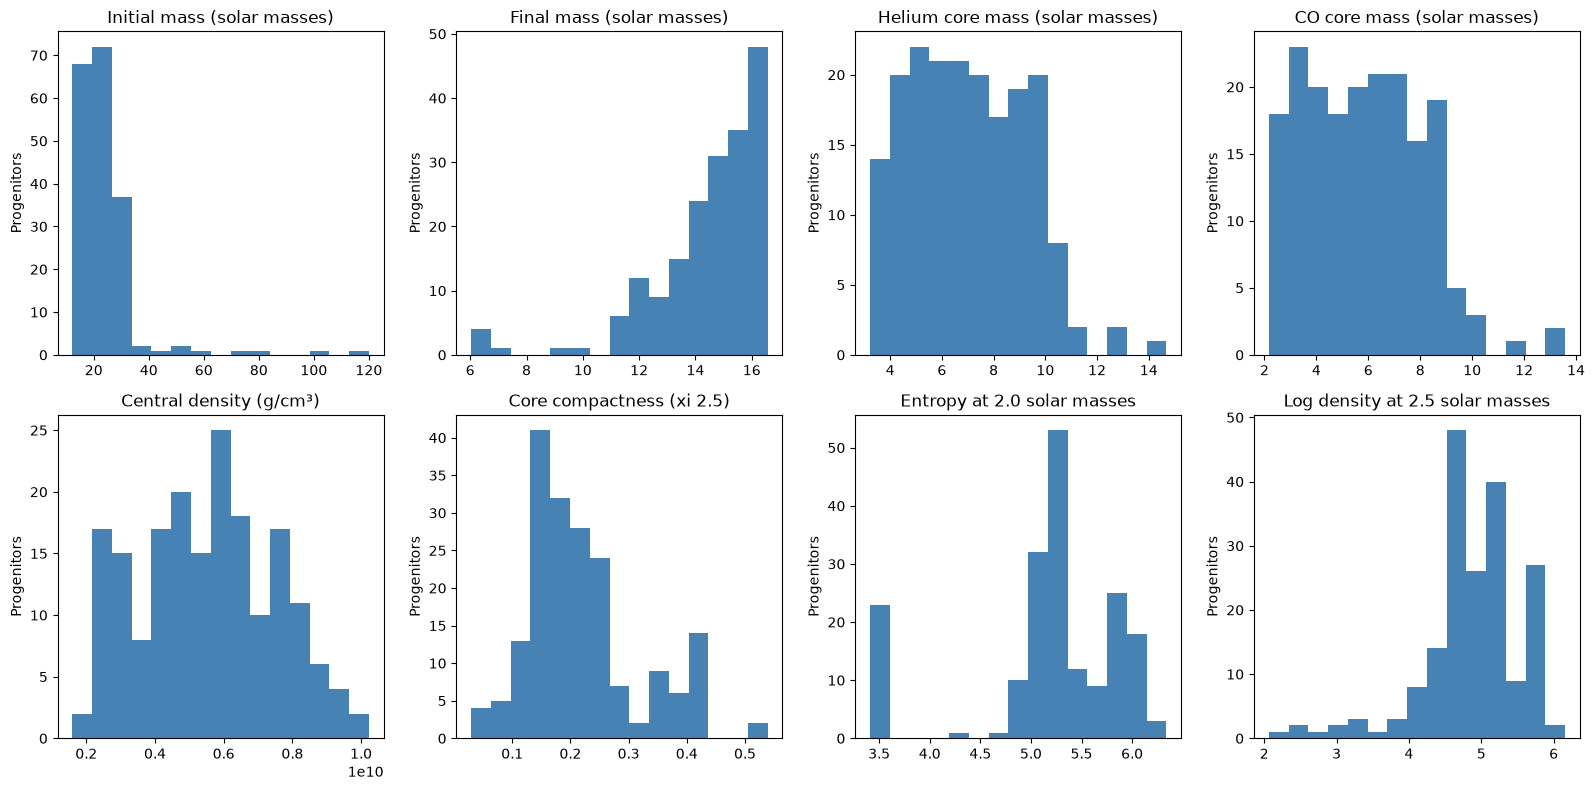

In [349]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (column, label) in zip(axes.flat, selected_features.items()):
    ax.hist(eda_data[column], bins=15, color="steelblue")
    ax.set_title(label)
    ax.set_xlabel("")
    ax.set_ylabel("Progenitors")

fig.tight_layout()
plt.show()

- **Initial mass:** Most values are between 10 and 40 solar masses, with a few much higher values.
- **Final mass:** Most values are around 14–16.5 solar masses, with a smaller group below 10.
- **Helium core mass:** Most values fall between 4 and 10 solar masses. A few stars have much larger helium cores.
- **CO core mass:** Most values fall between 3 and 9 solar masses, with a small number above 11.
- **Central density:** Values are spread across the range without a clearly separated group.
- **Core compactness at 2.5 solar masses:** Most stars have values below 0.3. A smaller group exceeds 0.3, and the largest values are slightly above 0.5.
- **Entropy at 2.0 solar masses:** Most stars are near 5–6, while a smaller group is near 3.5.
- **Log density at 2.5 solar masses:** Most values are near 4.5–5.5, with a few much lower values.

## Correlation between features and target score

I include `target_score` to explore linear relationships with the selected features. A value near zero does not rule out a nonlinear relationship.

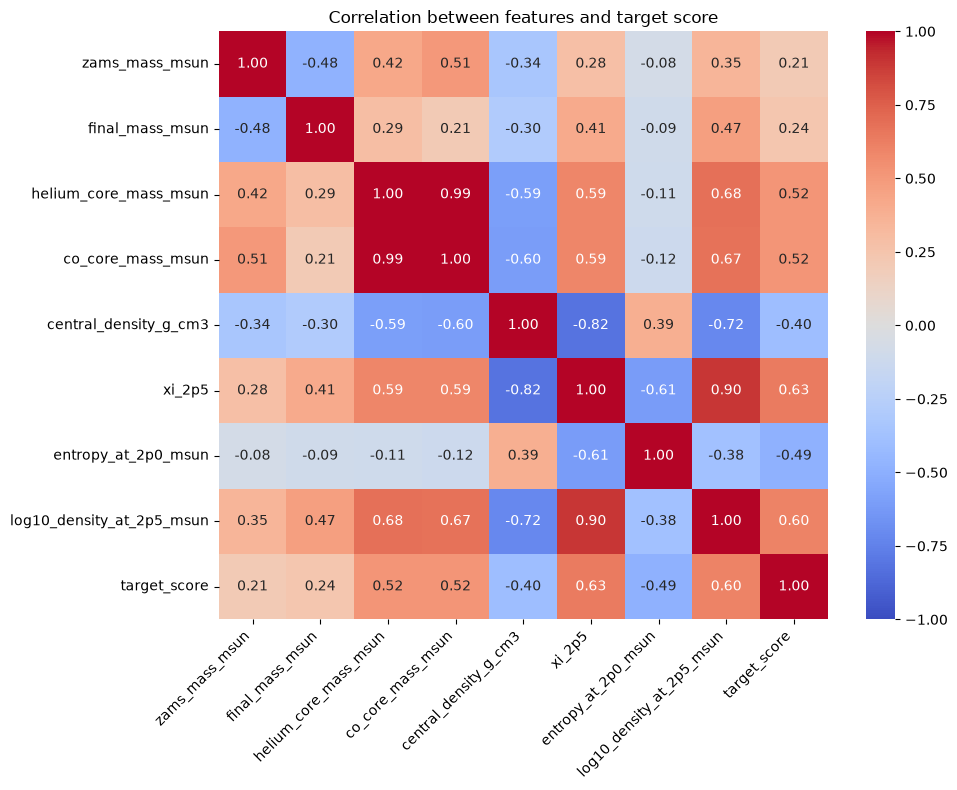

In [350]:
correlation_matrix = eda_data[list(selected_features) + ["target_score"]].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between features and target score")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [351]:
target_correlation = correlation_matrix["target_score"].drop("target_score")
target_ranking = pd.DataFrame({
    "correlation": target_correlation,
    "absolute_correlation": target_correlation.abs(),
})
display(target_ranking.sort_values("absolute_correlation", ascending=False).round(2))

,correlation,absolute_correlation
xi_2p5,0.63,0.63
log10_density_at_2p5_msun,0.60,0.60
helium_core_mass_msun,0.52,0.52
co_core_mass_msun,0.52,0.52
entropy_at_2p0_msun,-0.49,0.49
central_density_g_cm3,-0.40,0.40
final_mass_msun,0.24,0.24
zams_mass_msun,0.21,0.21


The strongest correlations with `target_score` are for compactness at 2.5 solar masses (0.63) and log density at the same mass (0.60). The helium and CO core masses follow at about 0.52. Entropy at 2.0 solar masses is negatively correlated with the score (-0.49). Initial and final mass have weaker linear correlations (0.21 and 0.24).

Some features are also related to each other. Helium and CO core masses are very closely correlated (0.99), as are compactness and log density at 2.5 solar masses (0.90). The four variables are related, but the correlations between the two pairs are lower, about 0.59 to 0.68. Central density has a strong negative correlation with compactness (-0.82). Entropy is moderately related to compactness (-0.61), but barely related to the two core masses.

These correlations describe linear relationships in this sample. They do not by themselves decide which features to keep.

## Constant features

A feature with the same value for every progenitor cannot help distinguish different outcomes. I check for these before choosing the model inputs.

In [352]:
selected_progenitors = features[features["model"].isin(reference_models)]

print("Constant columns:")
for column in selected_progenitors.columns:
    if column != "model" and selected_progenitors[column].nunique() == 1:
        print(f"{column}: {selected_progenitors[column].iloc[0]}")

Constant columns:
progenitor_family: s


`progenitor_family` is `s` for all 187 selected progenitors. It has no variation in this sample, so I remove it from the EDA table.

In [353]:
eda_data = eda_data.drop(columns=["progenitor_family"])

## Conclusion

The four selected engines share 187 progenitors. They agree on 149 outcomes and disagree on 38. The feature plots show overlap between NS and BH consensus, while compactness and density near 2.5 solar masses show the clearest associations with the weighted score among the eight features examined.

For Gold, I keep all 44 remaining numeric pre-collapse features. I removed `surface_fe56` because it is entirely missing, `zone_count` because it describes the profile resolution, and `progenitor_family` because it is constant for these 187 stars. The three unsupported core-mass estimates were already removed from Silver. Some retained features are strongly correlated, so I will review redundancy during modeling. `model` is an identifier and `target_score` is the target.

In [ ]:
eda_data.to_csv("../data/gold/progenitor_gold.csv", index=False)
print(f"Gold dataset saved: {eda_data.shape[0]} rows, {eda_data.shape[1]} columns")

Gold dataset saved: 187 rows, 46 columns
